# Paper 18: Mamba: Linear-Time Sequence Modeling with Selective State Spaces
**Authors**: Albert Gu, Tri Dao (Carnegie Mellon University & Princeton University, Dec 2023)

---

## 1. The Historical Breaking Point: Quadratic Attention vs. LTI Amnesia
Transformers scale quadratically ($O(L^2)$) with sequence length and require an $O(L)$ KV-cache during autoregressive generation.

Linear Time-Invariant (LTI) State Space Models (like S4) achieved $O(L)$ training via convolution and $O(1)$ inference. However, because their transition matrices $(A, B, C)$ were **constant across time**, they applied identical filtering to every token regardless of content. As a result, LTI models could not:
1. **Filter out irrelevant filler words**
2. **Selectively store key tokens for later recall (Associative Recall & In-Context Learning)**

## 2. The Thought Experiment: Dynamic Step Size $\Delta_t$
Mamba introduces **Selective State Spaces (S6)** by parameterizing $B_t$, $C_t$, and the discretization step size $\Delta_t$ directly from the current input $x_t$:
$$\bar{A}_t = \exp(\Delta_t A), \quad \bar{B}_t = \Delta_t B_t$$

- **Large $\Delta_t$**: $\bar{A}_t \to 0$, resetting the past hidden state and prioritizing the current token $x_t$.
- **Small $\Delta_t$**: $\bar{A}_t \to I$, preserving past memory unchanged and ignoring the current input $x_t$.

In this notebook, you will explore:
1. Discretization dynamics and the selective filtering effect
2. The selective scan recurrence (`selective_scan`)
3. The complete `MambaBlock` with causal convolution and SiLU gating
4. Causal language modeling with `MambaLM`

---
## Setup & Autoreload

In [1]:
%load_ext autoreload
%autoreload 2

import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from model import (
    MambaConfig,
    selective_scan,
    SelectiveSSM,
    MambaBlock,
    MambaLM,
)

print(f"PyTorch version: {torch.__version__}")

PyTorch version: 2.14.1+cpu


---
## 1. Discretization Dynamics & The Selective Gate
Let's visualize how the step size $\Delta$ controls the state decay $\bar{A} = \exp(\Delta A)$.
When $\Delta$ is tiny, the hidden state retains memory across many steps. When $\Delta$ spikes, past memory decays instantly!

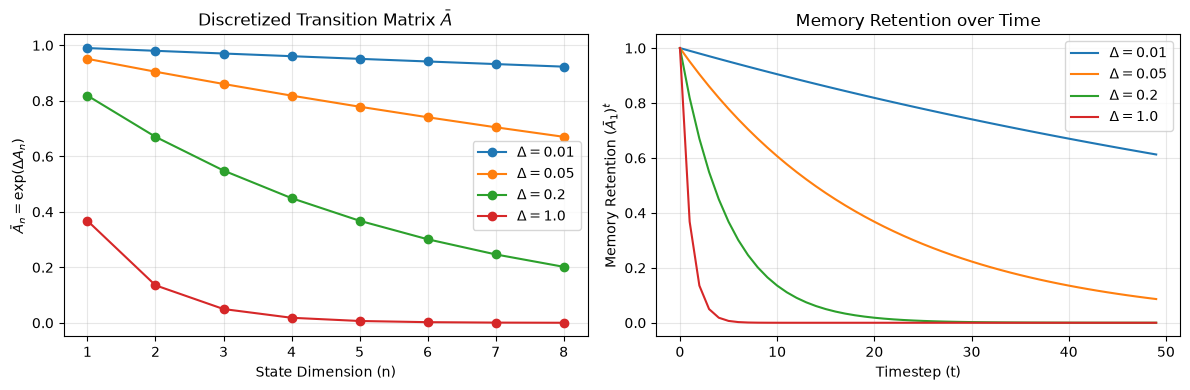

In [3]:
# Continuous diagonal A (negative eigenvalues)
A = -torch.arange(1, 9, dtype=torch.float32)  # 8 state dimensions

# Compare decay curves for small delta vs large delta
deltas = [0.01, 0.05, 0.2, 1.0]
timesteps = 50

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot A_bar across state dimensions for various deltas
for d in deltas:
    A_bar = torch.exp(d * A)
    axes[0].plot(range(1, 9), A_bar.numpy(), marker="o", label=rf"$\Delta = {d}$")
axes[0].set_xlabel("State Dimension (n)")
axes[0].set_ylabel(r"$\bar{A}_n = \exp(\Delta A_n)$")
axes[0].set_title(r"Discretized Transition Matrix $\bar{A}$")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Simulate exponential decay over time: h_t = (A_bar)^t * h_0
for d in deltas:
    A_bar_n1 = math.exp(d * A[0].item())  # slowest decaying mode (n=1)
    decay = [A_bar_n1 ** t for t in range(timesteps)]
    axes[1].plot(range(timesteps), decay, label=rf"$\Delta = {d}$")
axes[1].set_xlabel("Timestep (t)")
axes[1].set_ylabel(r"Memory Retention $(\bar{A}_1)^t$")
axes[1].set_title("Memory Retention over Time")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

---
## 2. Selective Scan Causality Verification
The selective scan computes $y_t = C_t h_t + D x_t$ where $h_t = \bar{A}_t h_{t-1} + \bar{B}_t x_t$.
Let's verify that the output at timestep $t$ strictly depends ONLY on tokens up to timestep $t$.

In [4]:
torch.manual_seed(42)
B, L, D, N = 1, 10, 16, 4
u = torch.randn(B, L, D)
delta = F.softplus(torch.randn(B, L, D))
A = -torch.exp(torch.randn(D, N))
B_mat = torch.randn(B, L, N)
C_mat = torch.randn(B, L, N)
D_skip = torch.randn(D)

y_original = selective_scan(u, delta, A, B_mat, C_mat, D_skip)

# Modify u only from timestep 6 onwards
u_perturbed = u.clone()
u_perturbed[:, 6:, :] += 50.0
y_perturbed = selective_scan(u_perturbed, delta, A, B_mat, C_mat, D_skip)

diff = (y_original - y_perturbed).abs().squeeze(0).mean(dim=-1)
print("Difference between original and perturbed outputs at each timestep:")
for t, d in enumerate(diff):
    print(f"  Step {t:2d}: Difference = {d.item():.6f} {'(Strictly zero: Causal)' if d.item() < 1e-6 else '(Altered by future)'}")

Difference between original and perturbed outputs at each timestep:
  Step  0: Difference = 0.000000 (Strictly zero: Causal)
  Step  1: Difference = 0.000000 (Strictly zero: Causal)
  Step  2: Difference = 0.000000 (Strictly zero: Causal)
  Step  3: Difference = 0.000000 (Strictly zero: Causal)
  Step  4: Difference = 0.000000 (Strictly zero: Causal)
  Step  5: Difference = 0.000000 (Strictly zero: Causal)
  Step  6: Difference = 52.645649 (Altered by future)
  Step  7: Difference = 188.060043 (Altered by future)
  Step  8: Difference = 39.530045 (Altered by future)
  Step  9: Difference = 46.840206 (Altered by future)


---
## 3. End-to-End Mamba Language Model & Single-Batch Overfit
Now let's verify that a complete `MambaLM` can learn to memorize and generate a sequence of token IDs autoregressively.

Training Mamba on single sequence overfit...
Initial loss: 29.4525 -> Final loss: 0.0008


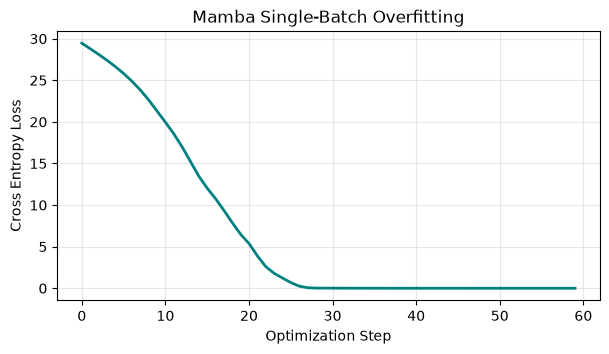

In [5]:
torch.manual_seed(42)

config = MambaConfig(d_model=32, d_state=8, d_conv=4, expand=2, vocab_size=30, n_layers=2)
model = MambaLM(config)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=1e-4)

# Target sequence to memorize
target_seq = torch.tensor([[1, 4, 9, 16, 25, 12, 18, 7, 21, 3, 14, 28]], dtype=torch.long)
inputs = target_seq[:, :-1]
targets = target_seq[:, 1:]

losses = []
print("Training Mamba on single sequence overfit...")
for step in range(60):
    optimizer.zero_grad()
    logits = model(inputs)
    loss = F.cross_entropy(logits.reshape(-1, config.vocab_size), targets.reshape(-1))
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

print(f"Initial loss: {losses[0]:.4f} -> Final loss: {losses[-1]:.4f}")

# Plot convergence
plt.figure(figsize=(7, 3.5))
plt.plot(losses, color="teal", linewidth=2)
plt.xlabel("Optimization Step")
plt.ylabel("Cross Entropy Loss")
plt.title("Mamba Single-Batch Overfitting")
plt.grid(True, alpha=0.3)
plt.show()

---
## 4. Autoregressive Sequence Generation
Let's prompt the trained model with the first 4 tokens and watch it complete the remaining sequence autoregressively!

In [6]:
prompt = target_seq[:, :4]
max_new = len(target_seq[0]) - 4
generated = model.generate(prompt, max_new_tokens=max_new, temperature=1e-5)

print(f"Ground Truth: {target_seq.tolist()[0]}")
print(f"Prompt:       {prompt.tolist()[0]}")
print(f"Generated:    {generated.tolist()[0]}")
match = (generated == target_seq).all().item()
print(f"Exact match:  {'PASS' if match else 'FAIL'}")

Ground Truth: [1, 4, 9, 16, 25, 12, 18, 7, 21, 3, 14, 28]
Prompt:       [1, 4, 9, 16]
Generated:    [1, 4, 9, 16, 25, 12, 18, 7, 21, 3, 14, 28]
Exact match:  PASS
